# NinjaPhonetics E2: 4群ベンチマーク音響プロソディ指標の分布解析

- 対象コホート: UK-Native, US-Native, JP-Accented, JP-Mora-Forced (各 n=10)
- 比較指標:
  1. %V (母音占有率 [%])
  2. %C (子音占有率 [%])
  3. nPVI_clipped (30msフロア補正済み正規化母音変動指標)
  4. Schwa Median (弱母音中央値 [ms])
  5. Schwa P75 (弱母音第3四分位数 [ms])
  6. Stressed / Unstressed 平均長比

In [9]:
!python generate_benchmarks.py



🎬 Processing Sentence: S1_stress
  Generating UK-Native (10 voices)...
  Generating US-Native (10 voices)...
  Generating JP-Accented (10 voices)...
  Generating JP-Mora-Forced (10 voices)...

🎬 Processing Sentence: S2_clusters
  Generating UK-Native (10 voices)...
  Generating US-Native (10 voices)...
  Generating JP-Accented (10 voices)...
  Generating JP-Mora-Forced (10 voices)...

🎬 Processing Sentence: S3_connected
  Generating UK-Native (10 voices)...
  Generating US-Native (10 voices)...
  Generating JP-Accented (10 voices)...
  Generating JP-Mora-Forced (10 voices)...

Generation complete. Total audio files: 120. Manifest: benchmarks/manifest.json


In [11]:

!python evaluate_benchmarks.py

Processing alignment for 120 items...
  [OK] [S1_stress] UK-Native_01_ArcherConver_male.wav | %V:  45.9% | P75:  46.8ms
  [OK] [S1_stress] UK-Native_02_BlondieConve_female.wav | %V:  47.0% | P75:  51.0ms
  [OK] [S1_stress] UK-Native_03_LucyFreshCas_female.wav | %V:  48.2% | P75:  57.5ms
  [OK] [S1_stress] UK-Native_04_Leon_male.wav       | %V:  46.9% | P75:  59.9ms
  [OK] [S1_stress] UK-Native_05_Archer_male.wav     | %V:  48.6% | P75:  56.9ms
  [OK] [S1_stress] UK-Native_06_Tom_male.wav        | %V:  47.0% | P75:  50.8ms
  [OK] [S1_stress] UK-Native_07_FraserFintec_male.wav | %V:  44.9% | P75:  59.9ms
  [OK] [S1_stress] UK-Native_08_NathanielNat_male.wav | %V:  47.7% | P75:  63.7ms
  [OK] [S1_stress] UK-Native_09_TylerPleasan_male.wav | %V:  45.9% | P75:  59.9ms
  [OK] [S1_stress] UK-Native_10_TrinityXConv_female.wav | %V:  46.9% | P75:  50.9ms
  [OK] [S1_stress] US-Native_01_RogerLaidBac_male.wav | %V:  46.2% | P75:  59.2ms
  [OK] [S1_stress] US-Native_02_WillRelaxedO_male.wav | %V: 

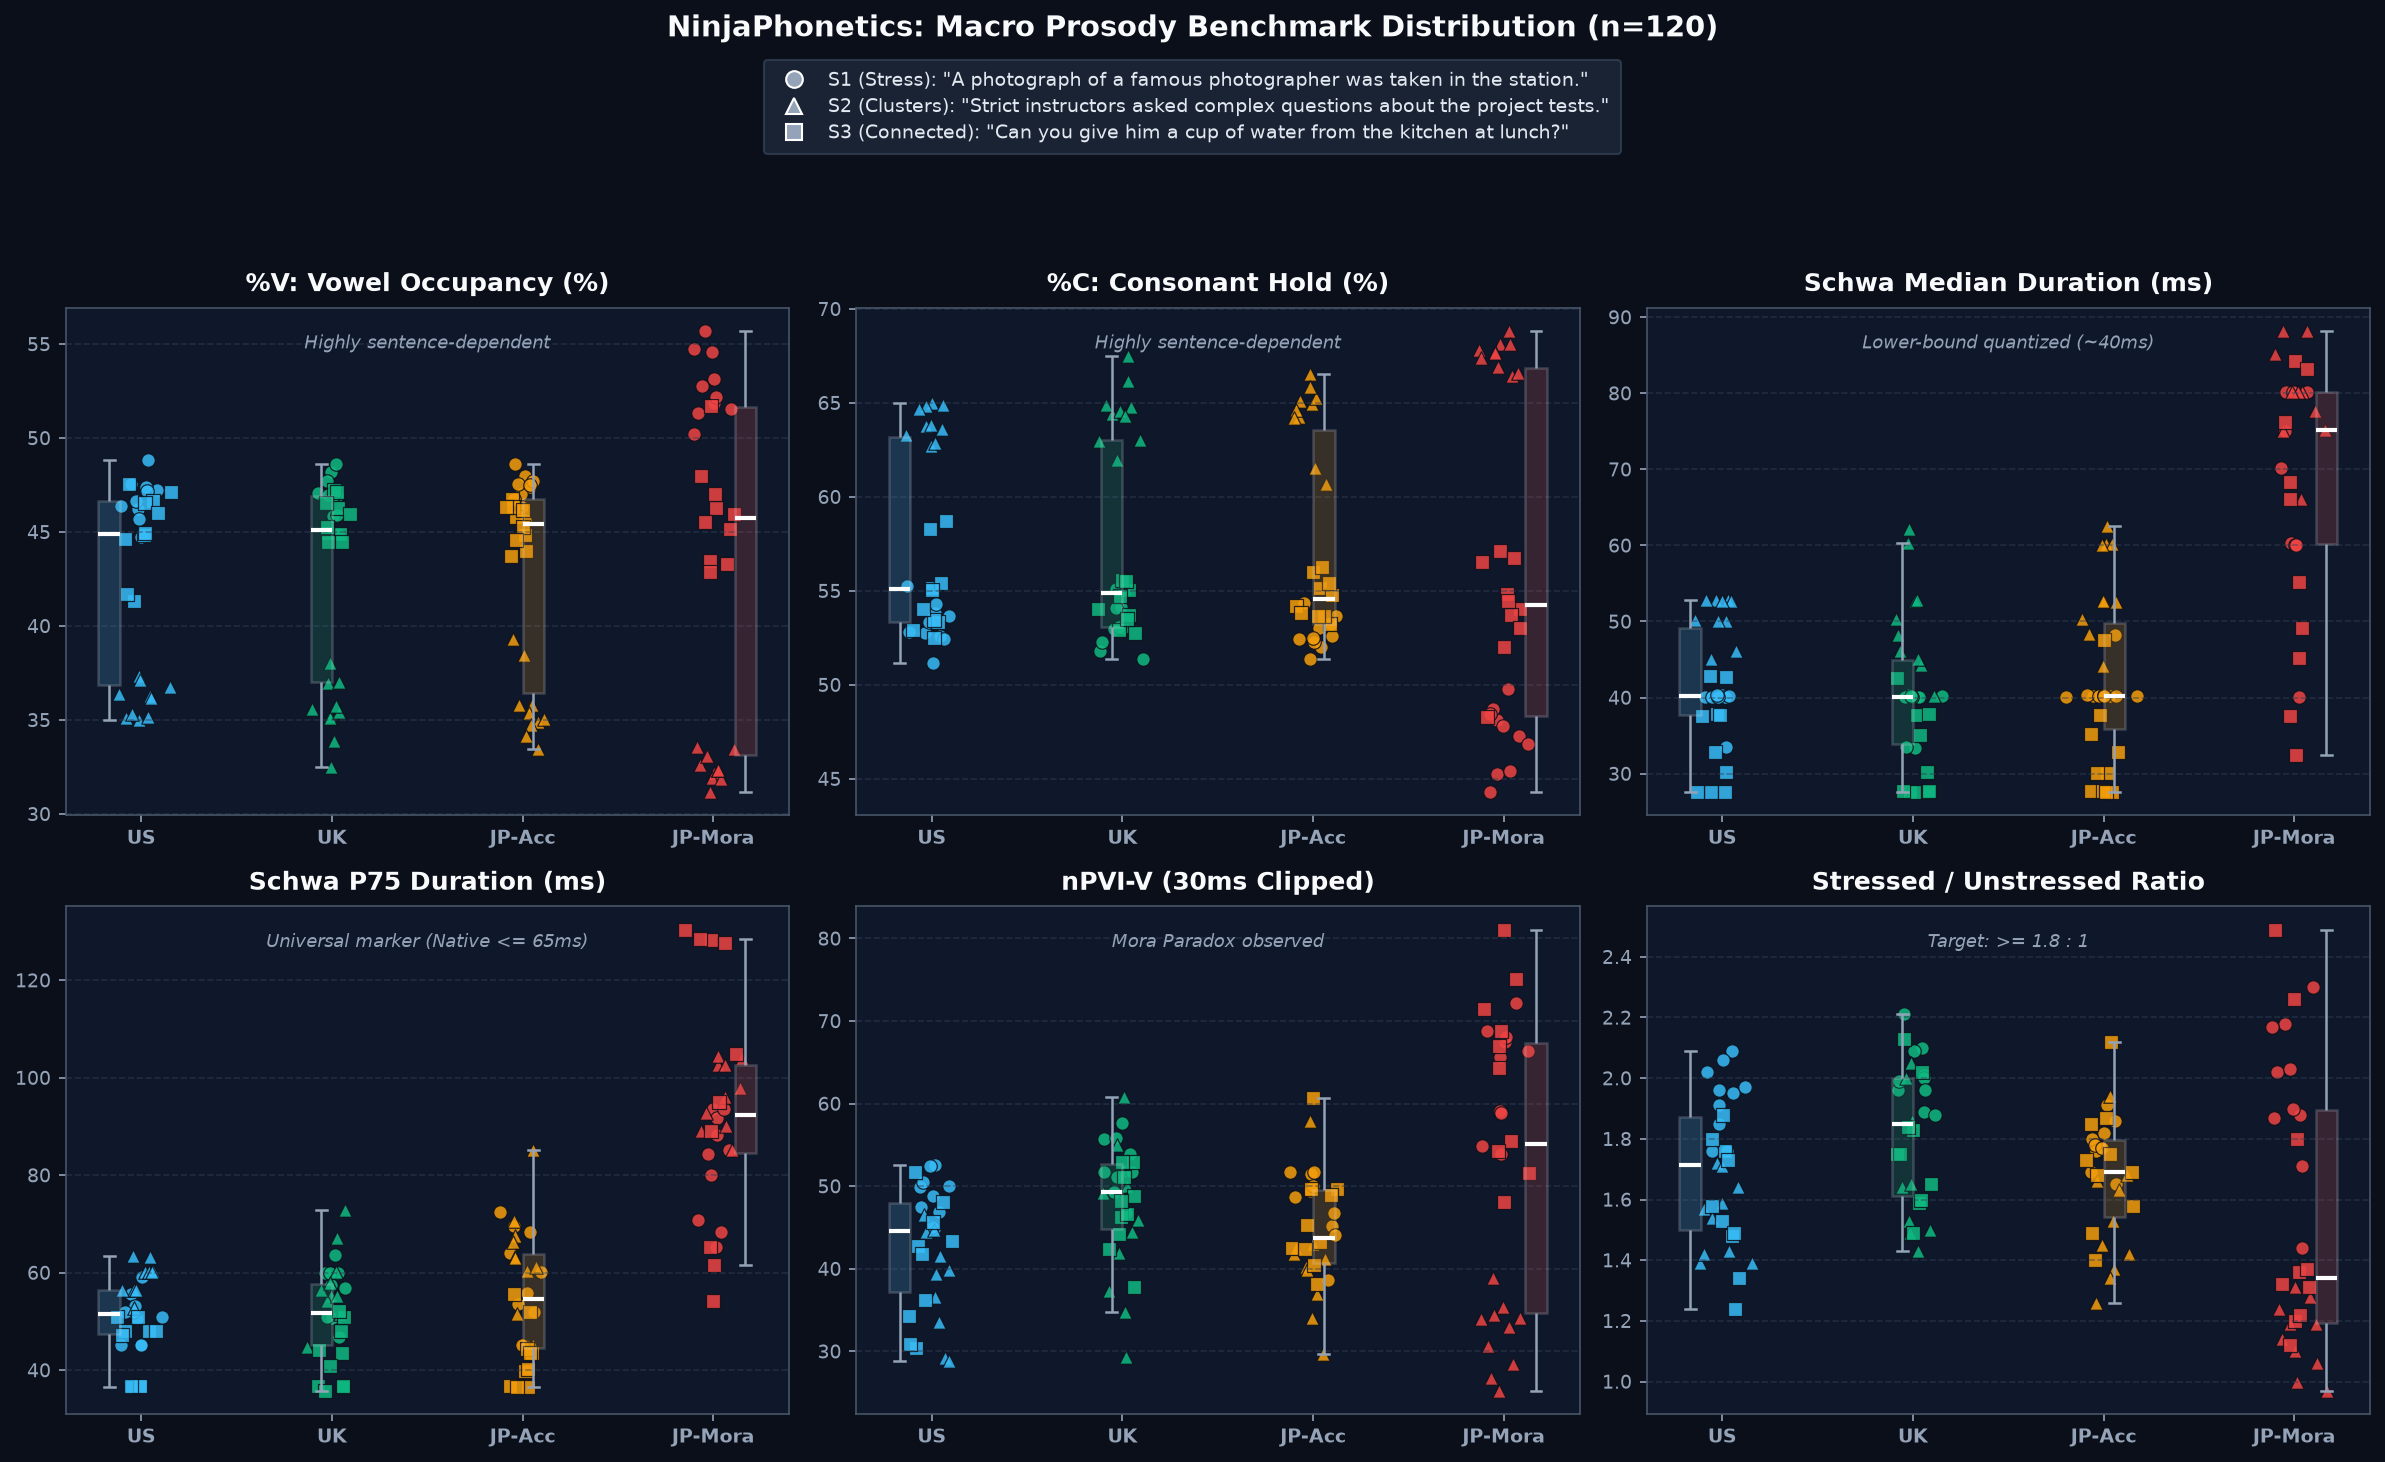

In [16]:
# 2. 例文キーと実際の英文全文、およびマーカー形状のマッピング（全文表示）
sentence_info = {
    "S1_stress": {
        "marker": "o",
        "label": 'S1 (Stress): "A photograph of a famous photographer was taken in the station."'
    },
    "S2_clusters": {
        "marker": "^",
        "label": 'S2 (Clusters): "Strict instructors asked complex questions about the project tests."'
    },
    "S3_connected": {
        "marker": "s",
        "label": 'S3 (Connected): "Can you give him a cup of water from the kitchen at lunch?"'
    }
}

# 3. 6大指標 Boxplot + 文章別マーカー散布（上部3行・全文凡例）
metrics_to_plot = [
    ("pct_v", "%V: Vowel Occupancy (%)", "Highly sentence-dependent"),
    ("pct_c", "%C: Consonant Hold (%)", "Highly sentence-dependent"),
    ("schwa_median_ms", "Schwa Median Duration (ms)", "Lower-bound quantized (~40ms)"),
    ("schwa_p75_ms", "Schwa P75 Duration (ms)", "Universal marker (Native <= 65ms)"),
    ("npvi_clipped", "nPVI-V (30ms Clipped)", "Mora Paradox observed"),
    ("s_u_ratio_mean", "Stressed / Unstressed Ratio", "Target: >= 1.8 : 1")
]

# 凡例が3行入るため、縦サイズを少し拡大 (16, 9.8)
fig, axes = plt.subplots(2, 3, figsize=(16, 9.8), dpi=150)
fig.patch.set_facecolor('#0B0F19')
axes = axes.flatten()

legend_handles = []

for idx, (col, title, subtitle) in enumerate(metrics_to_plot):
    ax = axes[idx]
    ax.set_facecolor('#0F172A')
    
    # 箱ひげ図
    sns.boxplot(
        data=df,
        x='cohort',
        y=col,
        hue='cohort',
        legend=False,
        order=cohort_order,
        palette=palette,
        ax=ax,
        width=0.45,
        boxprops=dict(alpha=0.20, edgecolor='#E2E8F0', linewidth=1.2),
        whiskerprops=dict(color='#94A3B8', linewidth=1.2),
        capprops=dict(color='#94A3B8', linewidth=1.2),
        medianprops=dict(color='#FFFFFF', linewidth=2.0),
        showfliers=False
    )
    
    # 文章ごとにマーカーを変えて散布
    for s_key, s_data in sentence_info.items():
        sub = df[df['sentence_key'] == s_key]
        for c_idx, c_name in enumerate(cohort_order):
            c_vals = sub[sub['cohort'] == c_name][col]
            jitter = np.random.normal(0, 0.06, size=len(c_vals))
            ax.scatter(
                c_idx + jitter, c_vals,
                color=palette[c_name],
                marker=s_data["marker"],
                s=42, alpha=0.85, edgecolors='#0B0F19', linewidth=0.6
            )
            # 最初のサブプロットで凡例用の白いダミーシンボルを作成
            if idx == 0 and c_idx == 0:
                h = plt.Line2D([0], [0], marker=s_data["marker"], color='w', 
                               markerfacecolor='#94A3B8', markersize=8, 
                               linestyle='None', label=s_data["label"])
                legend_handles.append(h)
            
    ax.set_title(title, fontsize=12, fontweight='bold', color='#F8FAFC', pad=8)
    ax.text(0.5, 0.92, subtitle, transform=ax.transAxes, ha='center',
            fontsize=8.5, color='#94A3B8', style='italic')
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(colors='#94A3B8', labelsize=9)
    ax.grid(True, axis='y')
    ax.set_xticks(range(len(cohort_order)))
    ax.set_xticklabels(["US", "UK", "JP-Acc", "JP-Mora"], rotation=0, fontweight='bold')

# 枠外上部に3行（ncol=1）で全文を整列表示
fig.legend(
    handles=legend_handles,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.965),
    ncol=1,
    frameon=True,
    facecolor='#1E293B',
    edgecolor='#334155',
    fontsize=9.0,
    labelcolor='#E2E8F0',
    borderpad=0.6,
    labelspacing=0.4
)

plt.suptitle("NinjaPhonetics: Macro Prosody Benchmark Distribution (n=120)", 
             fontsize=14, fontweight='bold', color='#F8FAFC', y=0.99)

# 凡例3行分の高さを空けるため、プロット描画領域の上限を 0.865 に設定
plt.tight_layout(rect=[0, 0, 1, 0.865])
plt.savefig("benchmarks/prosody_distribution_legend.png", facecolor=fig.get_facecolor(), bbox_inches='tight')
plt.show()

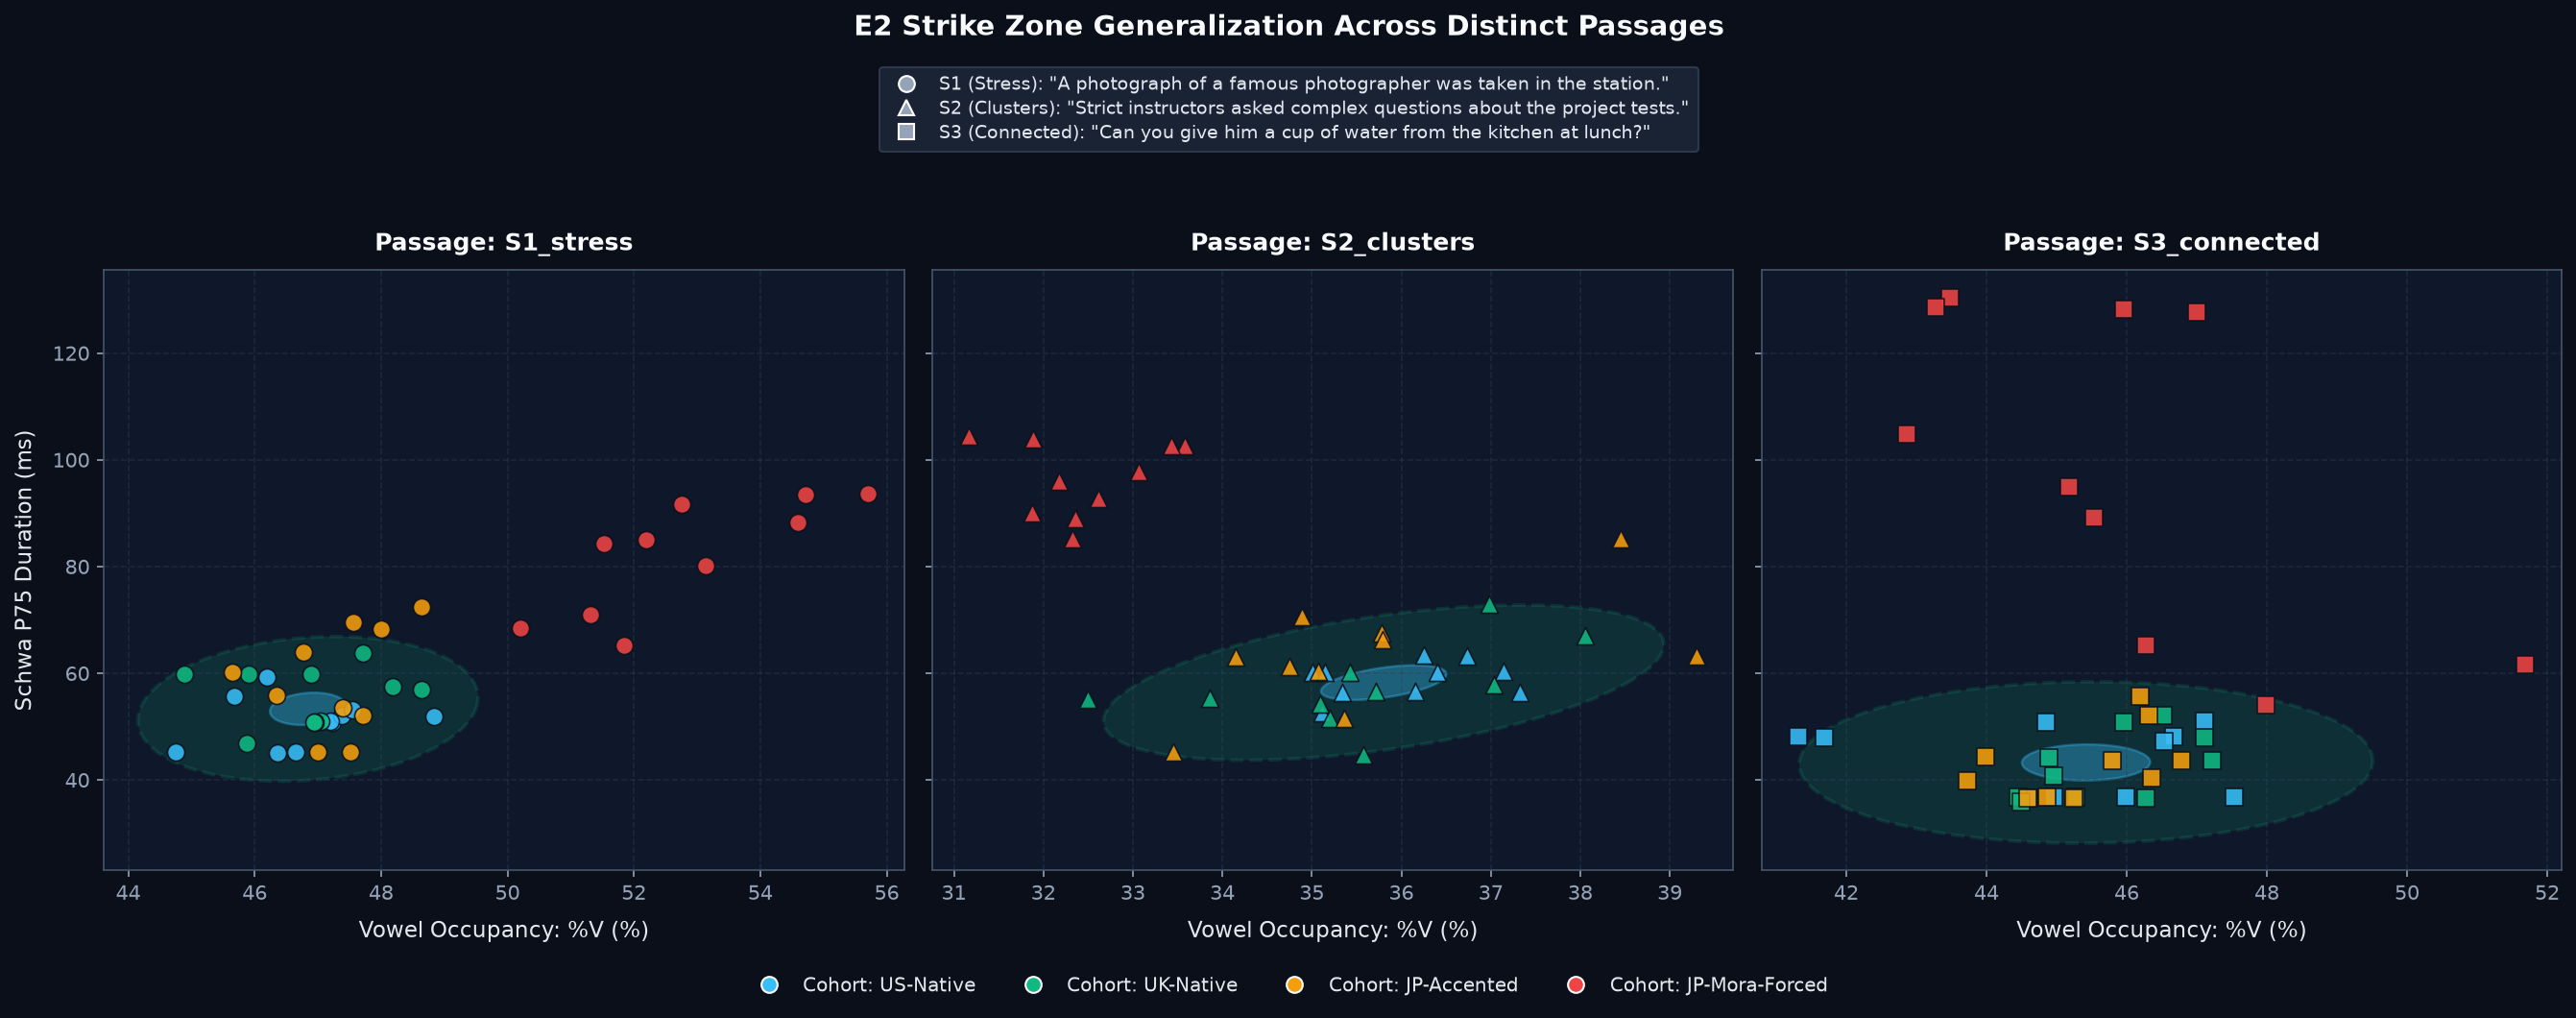

In [20]:
# %%
# 3. 2D Scatter Plots with 95% Strike Zone Ellipses (1 x 3 Facet with 3-line full text legend)
def draw_confidence_ellipse(x, y, ax, n_std=2.447, facecolor='#10B981', alpha=0.15, **kwargs):
    x, y = np.asarray(x), np.asarray(y)
    if len(x) < 3:
        return None
    cov = np.cov(x, y)
    vals, vecs = np.linalg.eigh(cov)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]
    theta = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
    width, height = 2 * n_std * np.sqrt(np.maximum(vals, 0))
    ellipse = Ellipse(
        xy=(np.mean(x), np.mean(y)),
        width=width,
        height=height,
        angle=theta,
        facecolor=facecolor,
        alpha=alpha,
        **kwargs
    )
    return ax.add_patch(ellipse)

fig, axes = plt.subplots(1, 3, figsize=(18, 6.8), dpi=150, sharey=True)
fig.patch.set_facecolor('#0B0F19')

scatter_legend_handles = []

for s_idx, (s_key, s_data) in enumerate(sentence_info.items()):
    ax = axes[s_idx]
    ax.set_facecolor('#0F172A')
    sub_df = df[df['sentence_key'] == s_key]
    
    # Calculate 95% Native Strike Zone Ellipse
    native_sub = sub_df[sub_df['cohort'].isin(["US-Native", "UK-Native"])]
    if len(native_sub) >= 3:
        draw_confidence_ellipse(
            native_sub['pct_v'], 
            native_sub['schwa_p75_ms'], 
            ax, 
            n_std=2.447, 
            facecolor='#10B981', 
            alpha=0.15, 
            edgecolor='#10B981', 
            linestyle='--', 
            linewidth=1.8
        )
        draw_confidence_ellipse(
            native_sub['pct_v'], 
            native_sub['schwa_p75_ms'], 
            ax, 
            n_std=2.447 / np.sqrt(len(native_sub)), 
            facecolor='#38BDF8', 
            alpha=0.35, 
            edgecolor='#38BDF8', 
            linewidth=1.2
        )

    # Plot cohort points using the sentence-specific marker
    for c_name in cohort_order:
        c_sub = sub_df[sub_df['cohort'] == c_name]
        ax.scatter(
            c_sub['pct_v'], c_sub['schwa_p75_ms'],
            color=palette[c_name],
            marker=s_data["marker"],
            s=75, alpha=0.88, edgecolors='#0B0F19', linewidth=0.8,
            zorder=3
        )
        
    ax.set_title(f"Passage: {s_key}", fontsize=12, fontweight='bold', color='#F8FAFC', pad=10)
    ax.set_xlabel("Vowel Occupancy: %V (%)", fontsize=11, color='#E2E8F0', labelpad=8)
    if s_idx == 0:
        ax.set_ylabel("Schwa P75 Duration (ms)", fontsize=11, color='#E2E8F0', labelpad=8)
    
    ax.tick_params(colors='#94A3B8')
    ax.grid(True, linestyle='--', alpha=0.4, color='#334155')

    # Construct clean legend entries with full sentence strings
    h = plt.Line2D([0], [0], marker=s_data["marker"], color='w', 
                   markerfacecolor='#94A3B8', markersize=8, 
                   linestyle='None', label=s_data["label"])
    scatter_legend_handles.append(h)

# Add cohort color indicators to the legend handles
for c_name in cohort_order:
    h_c = plt.Line2D([0], [0], marker='o', color='w',
                     markerfacecolor=palette[c_name], markersize=8,
                     linestyle='None', label=f"Cohort: {c_name}")
    scatter_legend_handles.append(h_c)

# 3-line sentence legend + cohort indicators
fig.legend(
    handles=scatter_legend_handles[:3],
    loc='upper center',
    bbox_to_anchor=(0.5, 0.985),
    ncol=1,
    frameon=True,
    facecolor='#1E293B',
    edgecolor='#334155',
    fontsize=9.0,
    labelcolor='#E2E8F0',
    borderpad=0.5,
    labelspacing=0.35
)

# Bottom cohort color key
fig.legend(
    handles=scatter_legend_handles[3:],
    loc='lower center',
    bbox_to_anchor=(0.5, 0.01),
    ncol=4,
    frameon=False,
    fontsize=9.5,
    labelcolor='#E2E8F0'
)

plt.suptitle("E2 Strike Zone Generalization Across Distinct Passages", 
             fontsize=14, fontweight='bold', color='#F8FAFC', y=1.03)
plt.tight_layout(rect=[0, 0.06, 1, 0.88])
plt.savefig("benchmarks/prosody_2d_strike_zone_comparison.png", facecolor=fig.get_facecolor(), bbox_inches='tight')
plt.show()

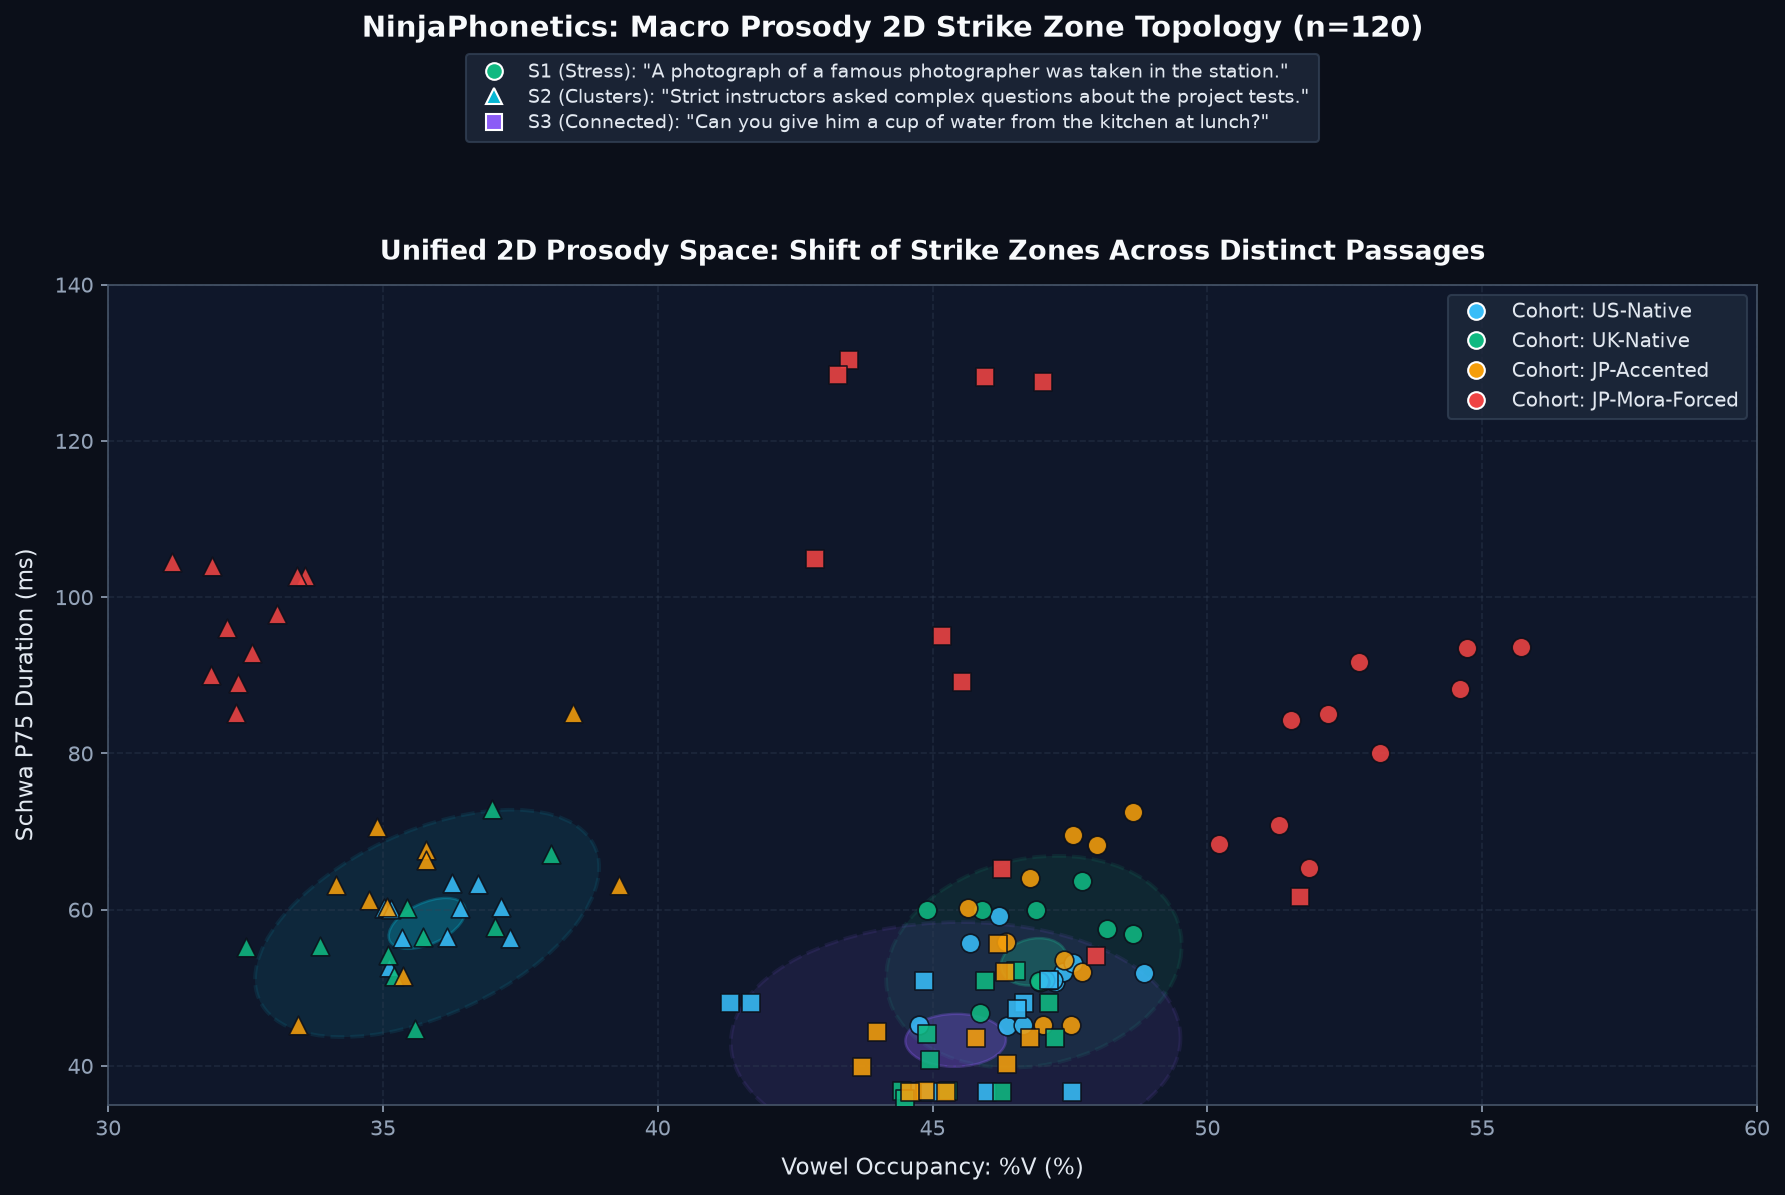

In [19]:
# %%
# 3. 統合 2D Scatter Plot（3文の Strike Zone 楕円 & 全データ点を1枚に集約）

fig, ax = plt.subplots(figsize=(12, 8), dpi=150)
fig.patch.set_facecolor('#0B0F19')
ax.set_facecolor('#0F172A')

# 楕円描画用の色定義（文ごとにストライクゾーンの境界色を微調整）
zone_colors = {
    "S1_stress": "#10B981",       # エメラルドグリーン
    "S2_clusters": "#06B6D4",     # シアン
    "S3_connected": "#8B5CF6"     # パープル
}

# 1. 3つの文それぞれの 95% Native Strike Zone (共分散楕円) を描画
for s_key, s_data in sentence_info.items():
    sub_df = df[df['sentence_key'] == s_key]
    native_sub = sub_df[sub_df['cohort'].isin(["US-Native", "UK-Native"])]
    
    if len(native_sub) >= 3:
        # 95% 許容ゾーン (n_std = 2.447)
        draw_confidence_ellipse(
            native_sub['pct_v'], 
            native_sub['schwa_p75_ms'], 
            ax, 
            n_std=2.447, 
            facecolor=zone_colors[s_key], 
            alpha=0.10, 
            edgecolor=zone_colors[s_key], 
            linestyle='--', 
            linewidth=1.8
        )
        # 95% 中心点 (Mean Centroid CI)
        draw_confidence_ellipse(
            native_sub['pct_v'], 
            native_sub['schwa_p75_ms'], 
            ax, 
            n_std=2.447 / np.sqrt(len(native_sub)), 
            facecolor=zone_colors[s_key], 
            alpha=0.30, 
            edgecolor=zone_colors[s_key], 
            linewidth=1.2
        )

# 2. 全120点をプロット（マーカー = 文、色 = コホート）
for s_key, s_data in sentence_info.items():
    sub_df = df[df['sentence_key'] == s_key]
    for c_name in cohort_order:
        c_sub = sub_df[sub_df['cohort'] == c_name]
        ax.scatter(
            c_sub['pct_v'], c_sub['schwa_p75_ms'],
            color=palette[c_name],
            marker=s_data["marker"],
            s=80, alpha=0.88, edgecolors='#0B0F19', linewidth=0.8,
            zorder=4
        )

# 3. 凡例ハンドルの構築（文章3行 + コホート4種）
legend_handles_sent = []
for s_key, s_data in sentence_info.items():
    h = plt.Line2D([0], [0], marker=s_data["marker"], color='w', 
                   markerfacecolor=zone_colors[s_key], markersize=8, 
                   linestyle='None', label=s_data["label"])
    legend_handles_sent.append(h)

legend_handles_cohort = []
for c_name in cohort_order:
    h_c = plt.Line2D([0], [0], marker='o', color='w',
                     markerfacecolor=palette[c_name], markersize=8,
                     linestyle='None', label=f"Cohort: {c_name}")
    legend_handles_cohort.append(h_c)

# 上部：3行の文章全文凡例（マーカー形状 ＆ ゾーンカラーに対応）
fig.legend(
    handles=legend_handles_sent,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.965),
    ncol=1,
    frameon=True,
    facecolor='#1E293B',
    edgecolor='#334155',
    fontsize=9.0,
    labelcolor='#E2E8F0',
    borderpad=0.5,
    labelspacing=0.35
)

# グラフ内：コホート色の凡例
legend_col = ax.legend(
    handles=legend_handles_cohort,
    loc='upper right',
    frameon=True,
    facecolor='#1E293B',
    edgecolor='#334155',
    fontsize=9.5
)
for text in legend_col.get_texts():
    text.set_color('#E2E8F0')

ax.set_title("Unified 2D Prosody Space: Shift of Strike Zones Across Distinct Passages", 
             fontsize=13, fontweight='bold', color='#F8FAFC', pad=12)
ax.set_xlabel("Vowel Occupancy: %V (%)", fontsize=11, color='#E2E8F0', labelpad=8)
ax.set_ylabel("Schwa P75 Duration (ms)", fontsize=11, color='#E2E8F0', labelpad=8)

# 全体が美しく収まる軸レンジ
ax.set_xlim(30, 60)
ax.set_ylim(35, 140)
ax.tick_params(colors='#94A3B8')
ax.grid(True, linestyle='--', alpha=0.4, color='#334155')

plt.suptitle("NinjaPhonetics: Macro Prosody 2D Strike Zone Topology (n=120)", 
             fontsize=14, fontweight='bold', color='#F8FAFC', y=0.99)
plt.tight_layout(rect=[0, 0, 1, 0.865])
plt.savefig("benchmarks/prosody_unified_scatter_single_plot.png", facecolor=fig.get_facecolor(), bbox_inches='tight')
plt.show()

In [18]:
# %%
# 4. Cohen's d Effect Size Ranking Table (Native vs JP-Mora)
def cohens_d(group1, group2):
    n1, n2 = len(group1), len(group2)
    s1, s2 = np.var(group1, ddof=1), np.var(group2, ddof=1)
    s_pooled = np.sqrt(((n1 - 1) * s1 + (n2 - 1) * s2) / (n1 + n2 - 2))
    if s_pooled == 0:
        return 0.0
    return abs(np.mean(group1) - np.mean(group2)) / s_pooled

rows = []
eval_cols = [
    ("pct_v", "%V (Vowel Occupancy)"),
    ("pct_c", "%C (Consonant Hold)"),
    ("schwa_p75_ms", "Schwa P75 Duration"),
    ("schwa_median_ms", "Schwa Median Duration"),
    ("npvi_clipped", "nPVI-V (30ms Clipped)"),
    ("s_u_ratio_mean", "Stressed / Unstressed Ratio")
]

for s_key in sentence_info.keys():
    sub = df[df['sentence_key'] == s_key]
    nat = sub[sub['cohort'].isin(["US-Native", "UK-Native"])]
    mor = sub[sub['cohort'] == "JP-Mora-Forced"]
    
    for col_key, col_label in eval_cols:
        d_val = cohens_d(nat[col_key], mor[col_key])
        rows.append({
            "Metric": col_label,
            "Sentence": s_key,
            "Cohen's d": round(d_val, 2)
        })

table_df = pd.DataFrame(rows).pivot(index="Metric", columns="Sentence", values="Cohen's d")
table_df["Mean_d"] = table_df.mean(axis=1).round(2)
table_df = table_df.sort_values(by="Mean_d", ascending=False)

# Display formatted Markdown / Pandas Table
table_df

Sentence,S1_stress,S2_clusters,S3_connected,Mean_d
Metric,,,,
Schwa P75 Duration,3.82,6.07,3.09,4.33
Schwa Median Duration,3.76,5.10,2.29,3.72
%C (Consonant Hold),4.45,2.95,0.25,2.55
%V (Vowel Occupancy),4.45,2.95,0.25,2.55
nPVI-V (30ms Clipped),2.79,1.30,2.36,2.15
Stressed / Unstressed Ratio,0.12,2.73,0.40,1.08
